# Behavior Analysis v3

This notebook closes the behavioral evidence loop before any activation analysis.

[实验设置与运行说明](../../../docs/experiment_notes/00_dataset_and_behavior/474fbc2b54b6d4c7.md)


In [1]:
# Run this helper cell once. Every later code cell uses %%cell_progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(total=total, initial=initial, desc=label, unit='cell', dynamic_ncols=True, leave=True)
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True)

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 12 tracked cells.')

Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 12 tracked cells.


## 1. Environment and cached artifacts

Run the notebook from top to bottom.


In [2]:
%%cell_progress 1/12 Mount Drive and locate project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (path for path in PROJECT_CANDIDATES if (path / 'toolkit' / 'pyproject.toml').is_file()),
    None,
)
assert PROJECT_ROOT is not None, 'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)

Mount Drive and locate project:   0%|          | 0/12 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/12 Install toolkit and import analysis stack
cell_stage('Installing local toolkit')
import importlib
import subprocess
import sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(TOOLKIT_ROOT)])
SRC_ROOT = TOOLKIT_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
importlib.invalidate_caches()

cell_stage('Importing scientific Python packages')
import hashlib
import json
import math
from datetime import datetime, timezone
from statistics import fmean

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

from visual_torque_toolkit.behavior import BehaviorModelArtifacts, analyze_behavior_comparison
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 100)
print('Behavior Analysis v3 imports: OK')

Install toolkit and import analysis stack:   8%|8         | 1/12 [00:00<?, ?cell/s]

Behavior Analysis v3 imports: OK


In [4]:
%%cell_progress 3/12 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all((path / name).is_file() for name in REQUIRED_DATASET_FILES)

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [member for member in bundle.infolist() if not member.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError('Run the Dataset v1 build/cache cell in the behavior notebook first.')
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)

Prepare Dataset v1 on local SSD:  17%|#6        | 2/12 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. Rebuild the scene-level comparison

This reuses the frozen permutation aggregation and 5,000 scene-clustered bootstrap replicates.


In [5]:
%%cell_progress 4/12 Locate predictions and rebuild comparison
cell_stage('Locating completed Qwen and Gemma runs')
MODEL_SPECS = (
    {
        'name': 'Qwen3.5-9B',
        'root': PROJECT_ROOT / 'results' / 'Qwen__Qwen3.5-9B' / 'behavior',
    },
    {
        'name': 'Gemma4-12B',
        'root': PROJECT_ROOT / 'results' / 'google__gemma-4-12B-it' / 'behavior',
    },
)
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'behavior_comparison_v3'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATHS = {}
models = []
for spec in MODEL_SPECS:
    paths = {
        'primary': spec['root'] / '01_primary_image_rule' / 'predictions.jsonl',
        'control': spec['root'] / '03_image_symbolic_control' / 'predictions.jsonl',
        'full_symbolic': spec['root'] / '04_full_symbolic_outcome' / 'predictions.jsonl',
    }
    missing = [str(path) for path in paths.values() if not path.is_file()]
    if missing:
        raise FileNotFoundError(
            f"{spec['name']} is incomplete. Missing:\n" + '\n'.join(missing)
        )
    MODEL_PATHS[spec['name']] = paths
    models.append(BehaviorModelArtifacts(
        name=spec['name'],
        primary_predictions=paths['primary'],
        control_predictions=paths['control'],
        full_symbolic_predictions=paths['full_symbolic'],
    ))
    print(spec['name'], '| primary/control/full-symbolic: found')

cell_stage('Running 5,000 scene-clustered bootstrap replicates')
analysis_outputs = analyze_behavior_comparison(
    dataset_dir=DATASET_DIR,
    models=tuple(models),
    output_dir=OUTPUT_DIR,
    bootstrap_replicates=5000,
    activation_scenes_per_stratum=30,
    seed=20260817,
)

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

cell_stage('Loading scene-level records')
summary = read_json(analysis_outputs['model_summary'])
paired = read_json(analysis_outputs['paired_model_comparison'])
diagnostics = read_json(analysis_outputs['perception_computation_diagnostics'])
predictions = pd.read_json(analysis_outputs['scene_level_predictions'], lines=True)
scenes = read_jsonl(DATASET_DIR / 'scenes.jsonl')
scene_by_id = {str(scene['scene_id']): scene for scene in scenes}
assert len(predictions) == 4200, len(predictions)
assert predictions.groupby('model_name')['scene_id'].nunique().eq(2100).all()
print('Comparison output:', OUTPUT_DIR)

Locate predictions and rebuild comparison:  25%|##5       | 3/12 [00:00<?, ?cell/s]

Qwen3.5-9B | primary/control/full-symbolic: found
Gemma4-12B | primary/control/full-symbolic: found
Comparison output: /content/drive/MyDrive/VisualTorque/results/behavior_comparison_v3


## 3. Main behavioral result

The primary outcome remains one token-prior-balanced semantic prediction per scene.


Render main behavioral figures:  33%|###3      | 4/12 [00:00<?, ?cell/s]

,model,scene_count,aggregated_accuracy,aggregated_ci_low,aggregated_ci_high,problem_type_macro_accuracy,raw_variant_accuracy,all_six_correct_rate,semantic_consistency_rate,torque_pearson,torque_spearman,predicted_A_share,predicted_B_share,predicted_C_share
0,Gemma4-12B,2100,0.7119,0.6933,0.7314,0.6181,0.7023,0.6262,0.8500,0.6579,0.6804,0.3081,0.3482,0.3437
1,Qwen3.5-9B,2100,0.6410,0.6205,0.6614,0.5899,0.5988,0.3129,0.4224,0.6671,0.6848,0.2558,0.2184,0.5258


{
  "Qwen3.5-9B__vs__Gemma4-12B": {
    "by_problem_type": {
      "balance": {
        "left_accuracy": 0.9666666666666667,
        "right_accuracy": 0.9666666666666667,
        "scene_count": 30
      },
      "compatible_weight_distance": {
        "left_accuracy": 0.95,
        "right_accuracy": 0.99,
        "scene_count": 300
      },
      "conflict_balance": {
        "left_accuracy": 0.0625,
        "right_accuracy": 0.0,
        "scene_count": 32
      },
      "conflict_distance": {
        "left_accuracy": 0.13432835820895522,
        "right_accuracy": 0.14925373134328357,
        "scene_count": 134
      },
      "conflict_weight": {
        "left_accuracy": 0.9776119402985075,
        "right_accuracy": 0.9552238805970149,
        "scene_count": 134
      },
      "distance": {
        "left_accuracy": 0.05333333333333334,
        "right_accuracy": 0.16,
        "scene_count": 150
      },
      "multi_stack": {
        "left_accuracy": 0.6333333333333333,
        "right_a

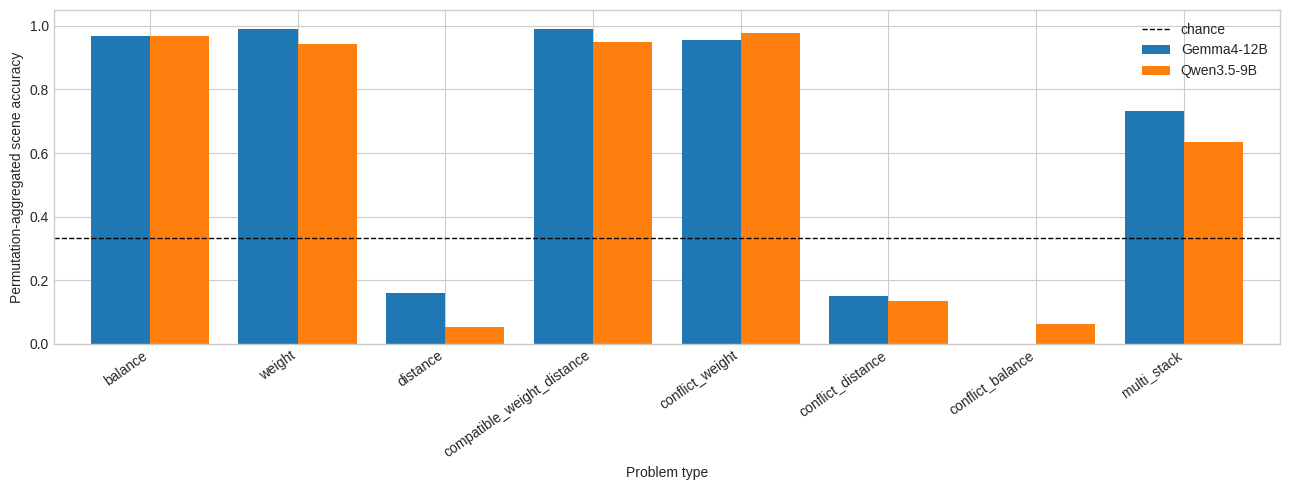

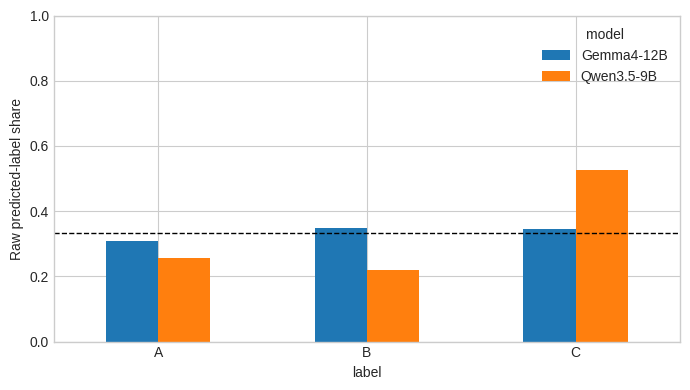

In [6]:
%%cell_progress 5/12 Render main behavioral figures
cell_stage('Building paper-facing summary table')
model_summary = pd.read_csv(analysis_outputs['model_summary_csv'])
problem = pd.read_csv(analysis_outputs['problem_type_comparison_csv'])
display(model_summary.round(4))
print(json.dumps(paired, indent=2)[:8000])

cell_stage('Plotting accuracy by problem type')
order = [
    'balance', 'weight', 'distance', 'compatible_weight_distance',
    'conflict_weight', 'conflict_distance', 'conflict_balance', 'multi_stack',
]
pivot = problem.pivot(index='problem_type', columns='model', values='aggregated_accuracy').reindex(order)
ax = pivot.plot(kind='bar', figsize=(13, 5), width=0.8)
ax.axhline(1 / 3, color='black', linestyle='--', linewidth=1, label='chance')
ax.set_ylabel('Permutation-aggregated scene accuracy')
ax.set_xlabel('Problem type')
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '01_problem_type_accuracy.png', dpi=180, bbox_inches='tight')
plt.show()

cell_stage('Plotting raw answer-label shares')
label_rows = []
for model, report in summary.items():
    for label, share in report['raw_predicted_label_shares'].items():
        label_rows.append({'model': model, 'label': label, 'share': share})
label_frame = pd.DataFrame(label_rows).pivot(index='label', columns='model', values='share')
ax = label_frame.plot(kind='bar', figsize=(7, 4))
ax.axhline(1 / 3, color='black', linestyle='--', linewidth=1)
ax.set_ylabel('Raw predicted-label share')
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '02_raw_label_shares.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Full symbolic decomposition

This is the missing v2 table.


Analyze full symbolic controls:  42%|####1     | 5/12 [00:00<?, ?cell/s]

,model,scene_count,image_accuracy,symbolic_accuracy,symbolic_minus_image_accuracy,symbolic_minus_image_scene_bootstrap_95_ci,semantic_agreement_rate
0,Gemma4-12B,2100,0.7119,0.8448,0.1329,"[0.11332142857142857, 0.1523809523809524]",0.7276
1,Qwen3.5-9B,2100,0.6410,0.6671,0.0262,"[0.0019047619047619048, 0.05047619047619047]",0.6443


,model,problem_type,scene_count,image_accuracy,symbolic_accuracy,symbolic_minus_image_accuracy
0,Gemma4-12B,balance,30,0.9667,1.0000,0.0333
8,Qwen3.5-9B,balance,30,0.9667,1.0000,0.0333
1,Gemma4-12B,compatible_weight_distance,300,0.9900,1.0000,0.0100
9,Qwen3.5-9B,compatible_weight_distance,300,0.9500,1.0000,0.0500
2,Gemma4-12B,conflict_balance,32,0.0000,0.7188,0.7188
10,Qwen3.5-9B,conflict_balance,32,0.0625,0.0000,-0.0625
3,Gemma4-12B,conflict_distance,134,0.1493,0.4403,0.2910
11,Qwen3.5-9B,conflict_distance,134,0.1343,0.5000,0.3657
4,Gemma4-12B,conflict_weight,134,0.9552,0.7313,-0.2239
12,Qwen3.5-9B,conflict_weight,134,0.9776,0.5000,-0.4776


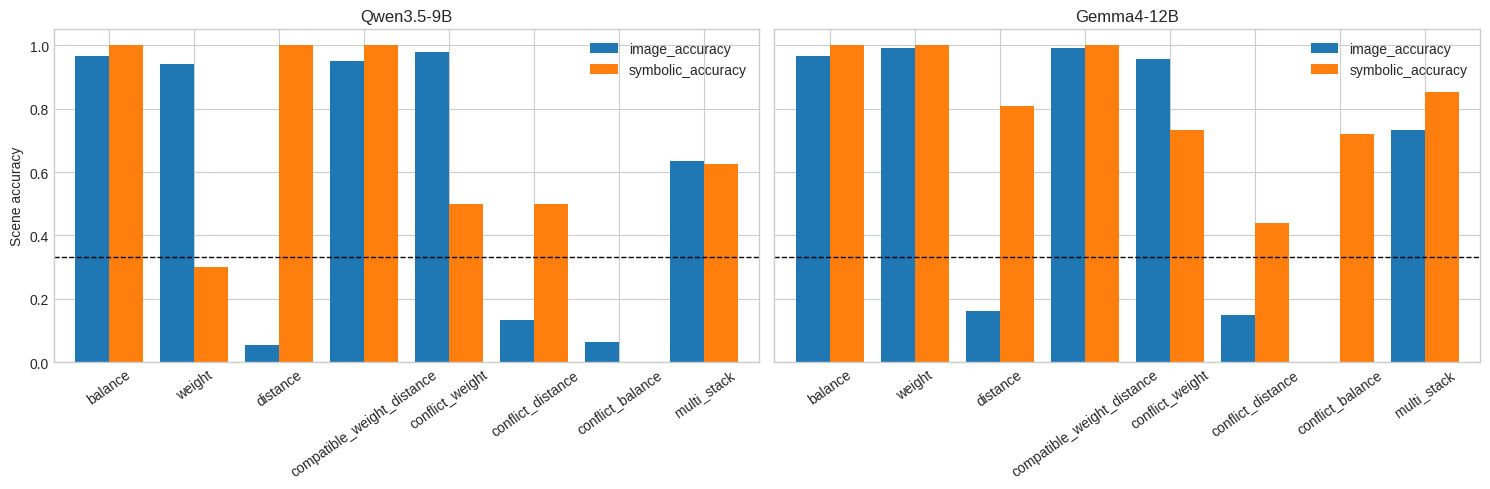

,model,question_kind,pair_count,scene_count,image_accuracy,symbolic_accuracy,symbolic_minus_image_accuracy,symbolic_minus_image_scene_bootstrap_95_ci,semantic_agreement_rate
0,Gemma4-12B,left_distance,96,96,0.2917,1.0000,0.7083,"[0.6145833333333334, 0.8020833333333334]",0.2917
1,Gemma4-12B,left_units,120,120,0.7583,0.9333,0.1750,"[0.1, 0.25]",0.7750
2,Gemma4-12B,outcome,720,120,0.6208,0.8153,0.1944,"[0.1125, 0.2777777777777778]",0.6292
3,Gemma4-12B,right_distance,96,96,0.6250,1.0000,0.3750,"[0.28125, 0.4791666666666667]",0.6250
4,Gemma4-12B,right_units,120,120,0.6833,0.9333,0.2500,"[0.1664583333333334, 0.3333333333333333]",0.6750
5,Qwen3.5-9B,left_distance,96,96,0.4479,1.0000,0.5521,"[0.4479166666666667, 0.6458333333333334]",0.4479
6,Qwen3.5-9B,left_units,120,120,0.8417,0.9333,0.0917,"[0.03333333333333333, 0.15]",0.8833
7,Qwen3.5-9B,outcome,720,120,0.5528,0.6167,0.0639,"[-0.020833333333333325, 0.1500347222222217]",0.5903
8,Qwen3.5-9B,right_distance,96,96,0.5208,1.0000,0.4792,"[0.375, 0.5731770833333295]",0.5208
9,Qwen3.5-9B,right_units,120,120,0.8417,0.8750,0.0333,"[-0.025, 0.09166666666666666]",0.8417


In [7]:
%%cell_progress 6/12 Analyze full symbolic controls
cell_stage('Tabulating all-scene image-versus-symbolic outcomes')
overall_rows = []
type_rows = []
for model, report in diagnostics.items():
    if 'full_outcome' not in report:
        raise RuntimeError(f'{model}: full symbolic outcome is missing.')
    overall = report['full_outcome']['overall']
    overall_rows.append({'model': model, **overall})
    for problem_type, values in report['full_outcome']['by_problem_type'].items():
        type_rows.append({'model': model, 'problem_type': problem_type, **values})

full_symbolic_overall = pd.DataFrame(overall_rows)
full_symbolic_by_type = pd.DataFrame(type_rows)
assert full_symbolic_overall['scene_count'].eq(2100).all(), full_symbolic_overall
full_symbolic_overall.to_csv(OUTPUT_DIR / 'full_symbolic_overall.csv', index=False)
full_symbolic_by_type.to_csv(OUTPUT_DIR / 'full_symbolic_by_problem_type.csv', index=False)
display(full_symbolic_overall[[
    'model', 'scene_count', 'image_accuracy', 'symbolic_accuracy',
    'symbolic_minus_image_accuracy', 'symbolic_minus_image_scene_bootstrap_95_ci',
    'semantic_agreement_rate',
]].round(4))
display(full_symbolic_by_type[[
    'model', 'problem_type', 'scene_count', 'image_accuracy',
    'symbolic_accuracy', 'symbolic_minus_image_accuracy',
]].sort_values(['problem_type', 'model']).round(4))

cell_stage('Plotting full symbolic decomposition')
figure, axes = plt.subplots(1, len(MODEL_SPECS), figsize=(15, 5), sharey=True)
for axis, spec in zip(np.atleast_1d(axes), MODEL_SPECS):
    frame = full_symbolic_by_type[full_symbolic_by_type['model'] == spec['name']].set_index('problem_type').reindex(order)
    frame[['image_accuracy', 'symbolic_accuracy']].plot(kind='bar', ax=axis, width=0.8)
    axis.axhline(1 / 3, color='black', linestyle='--', linewidth=1)
    axis.set_title(spec['name'])
    axis.set_xlabel('')
    axis.set_ylim(0, 1.05)
    axis.tick_params(axis='x', rotation=35)
    axis.set_ylabel('Scene accuracy')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '03_full_symbolic_by_problem_type.png', dpi=180, bbox_inches='tight')
plt.show()

cell_stage('Displaying primitive perception controls')
primitive_control = pd.read_csv(analysis_outputs['control_by_question_kind_csv'])
primitive_control.to_csv(OUTPUT_DIR / 'primitive_image_symbolic_control.csv', index=False)
display(primitive_control.round(4))

## 5. Heuristic signatures

The following analysis asks whether each model agrees with simple partial strategies, especially on scenes where a heuristic conflicts with the exact torque rule.


Quantify heuristic and shortcut signatures:  50%|#####     | 6/12 [00:00<?, ?cell/s]

Scene features:   0%|          | 0/2100 [00:00<?, ?scene/s]

,model,scope,heuristic,scene_count,heuristic_accuracy,model_heuristic_agreement,conflict_scene_count,model_accuracy_when_heuristic_conflicts,model_heuristic_agreement_when_conflict
1,Gemma4-12B,all,farthest_stack,2100,0.6267,0.4243,784,0.8431,0.0727
13,Qwen3.5-9B,all,farthest_stack,2100,0.6267,0.3890,784,0.7679,0.0931
3,Gemma4-12B,all,maximum_single_torque,2100,0.9124,0.6881,184,0.5272,0.2554
15,Qwen3.5-9B,all,maximum_single_torque,2100,0.9124,0.6405,184,0.3913,0.3859
2,Gemma4-12B,all,stack_count,2100,0.1176,0.1852,1853,0.7178,0.1209
14,Qwen3.5-9B,all,stack_count,2100,0.1176,0.2005,1853,0.6552,0.1560
0,Gemma4-12B,all,total_weight,2100,0.6681,0.8586,697,0.2439,0.6858
12,Qwen3.5-9B,all,total_weight,2100,0.6681,0.7619,697,0.2554,0.6198
9,Gemma4-12B,multi_stack,farthest_stack,1200,0.5850,0.4242,498,0.8313,0.0904
21,Qwen3.5-9B,multi_stack,farthest_stack,1200,0.5850,0.3900,498,0.7149,0.1285


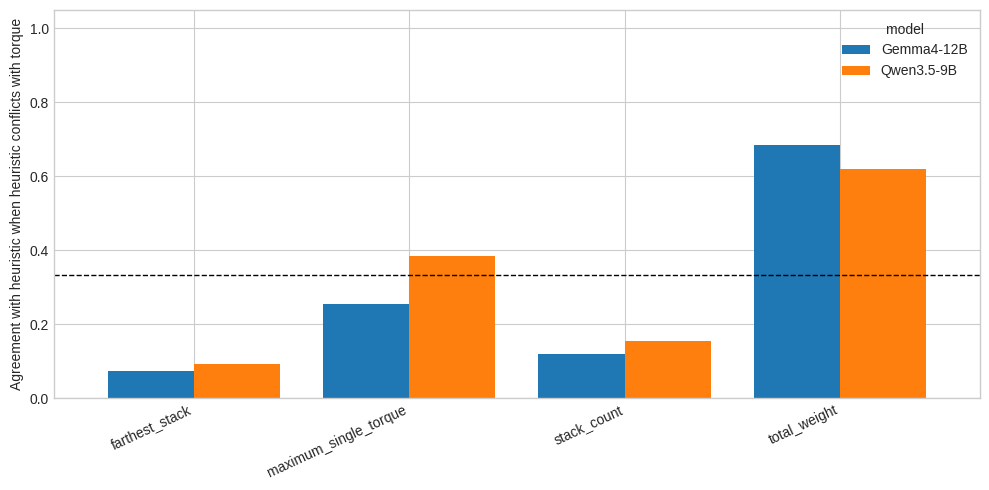

In [8]:
%%cell_progress 7/12 Quantify heuristic and shortcut signatures
cell_stage('Computing exact and heuristic scene features')
def compare_signed(value):
    if value > 0:
        return 'left'
    if value < 0:
        return 'right'
    return 'balanced'

def scene_features(scene):
    left = [stack for stack in scene['stacks'] if stack['side'] == 'left']
    right = [stack for stack in scene['stacks'] if stack['side'] == 'right']
    left_weight = sum(int(stack['units']) for stack in left)
    right_weight = sum(int(stack['units']) for stack in right)
    left_farthest = max((int(stack['distance']) for stack in left), default=0)
    right_farthest = max((int(stack['distance']) for stack in right), default=0)
    left_max_torque = max((int(stack['units']) * int(stack['distance']) for stack in left), default=0)
    right_max_torque = max((int(stack['units']) * int(stack['distance']) for stack in right), default=0)
    return {
        'scene_id': str(scene['scene_id']),
        'weight_diff': left_weight - right_weight,
        'farthest_distance_diff': left_farthest - right_farthest,
        'stack_count_diff': len(left) - len(right),
        'max_single_torque_diff': left_max_torque - right_max_torque,
        'oracle_net_torque': int(scene['derived']['net_torque']),
    }

features = pd.DataFrame([scene_features(scene) for scene in tqdm(scenes, desc='Scene features', unit='scene')])
analysis_frame = predictions.merge(features, on='scene_id', how='left', validate='many_to_one')
assert analysis_frame['oracle_net_torque'].notna().all()
assert (analysis_frame['oracle_net_torque'] == analysis_frame['net_torque']).all()

heuristics = {
    'total_weight': 'weight_diff',
    'farthest_stack': 'farthest_distance_diff',
    'stack_count': 'stack_count_diff',
    'maximum_single_torque': 'max_single_torque_diff',
}
rows = []
for model, model_frame in analysis_frame.groupby('model_name'):
    for scope, scoped in (
        ('all', model_frame),
        ('single_stack', model_frame[model_frame['problem_type'] != 'multi_stack']),
        ('multi_stack', model_frame[model_frame['problem_type'] == 'multi_stack']),
    ):
        for heuristic, column in heuristics.items():
            predicted = scoped[column].map(compare_signed)
            gold = scoped['gold_semantic'].astype(str)
            model_prediction = scoped['aggregated_predicted_semantic'].astype(str)
            conflict = predicted != gold
            rows.append({
                'model': model,
                'scope': scope,
                'heuristic': heuristic,
                'scene_count': len(scoped),
                'heuristic_accuracy': float((predicted == gold).mean()),
                'model_heuristic_agreement': float((model_prediction == predicted).mean()),
                'conflict_scene_count': int(conflict.sum()),
                'model_accuracy_when_heuristic_conflicts': (
                    float((model_prediction[conflict] == gold[conflict]).mean()) if conflict.any() else None
                ),
                'model_heuristic_agreement_when_conflict': (
                    float((model_prediction[conflict] == predicted[conflict]).mean()) if conflict.any() else None
                ),
            })

heuristic_report = pd.DataFrame(rows)
heuristic_report.to_csv(OUTPUT_DIR / 'heuristic_signature.csv', index=False)
display(heuristic_report.sort_values(['scope', 'heuristic', 'model']).round(4))

cell_stage('Plotting shortcut agreement on conflict scenes')
plot_data = heuristic_report[heuristic_report['scope'] == 'all'].pivot(
    index='heuristic', columns='model', values='model_heuristic_agreement_when_conflict'
)
ax = plot_data.plot(kind='bar', figsize=(10, 5), width=0.8)
ax.axhline(1 / 3, color='black', linestyle='--', linewidth=1)
ax.set_ylabel('Agreement with heuristic when heuristic conflicts with torque')
ax.set_ylim(0, 1.05)
ax.set_xlabel('')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '04_heuristic_conflict_agreement.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. What predicts the model's signed evidence?

Five-fold out-of-fold ridge regressions compare an exact-physics predictor, a shortcut-only predictor set, and their combination.


Fit out-of-fold margin diagnostics:  58%|#####8    | 7/12 [00:00<?, ?cell/s]

Margin models:   0%|          | 0/2 [00:00<?, ?model/s]

,model,specification,scene_count,oof_r2,oof_pearson,oof_mae,median_selected_alpha
0,Gemma4-12B,physics_only,2100,0.4321,0.6574,2.2995,1.0000
1,Gemma4-12B,shortcuts_only,2100,0.6306,0.7941,1.8066,3.1623
2,Gemma4-12B,physics_plus_shortcuts,2100,0.6303,0.7939,1.8074,3.1623
3,Qwen3.5-9B,physics_only,2100,0.4436,0.6660,0.5898,1.0000
4,Qwen3.5-9B,shortcuts_only,2100,0.6666,0.8165,0.4486,10.0000
5,Qwen3.5-9B,physics_plus_shortcuts,2100,0.6683,0.8175,0.4477,1.0000


,model,specification,feature,standardized_coefficient_mean,standardized_coefficient_sd
5,Gemma4-12B,physics_plus_shortcuts,oracle_net_torque,0.1605,0.1079
6,Gemma4-12B,physics_plus_shortcuts,weight_diff,2.6378,0.0376
7,Gemma4-12B,physics_plus_shortcuts,farthest_distance_diff,0.3257,0.0408
8,Gemma4-12B,physics_plus_shortcuts,stack_count_diff,-0.2281,0.0145
9,Gemma4-12B,physics_plus_shortcuts,max_single_torque_diff,0.3996,0.1040
15,Qwen3.5-9B,physics_plus_shortcuts,oracle_net_torque,-0.1578,0.0243
16,Qwen3.5-9B,physics_plus_shortcuts,weight_diff,0.5576,0.0067
17,Qwen3.5-9B,physics_plus_shortcuts,farthest_distance_diff,-0.0714,0.0077
18,Qwen3.5-9B,physics_plus_shortcuts,stack_count_diff,-0.0821,0.0063
19,Qwen3.5-9B,physics_plus_shortcuts,max_single_torque_diff,0.5177,0.0197


,model,problem_type,scene_count,torque_margin_pearson,torque_margin_spearman
0,Gemma4-12B,balance,30,NaN,NaN
8,Qwen3.5-9B,balance,30,NaN,NaN
1,Gemma4-12B,compatible_weight_distance,300,0.8911,0.7623
9,Qwen3.5-9B,compatible_weight_distance,300,0.9160,0.8279
2,Gemma4-12B,conflict_balance,32,NaN,NaN
10,Qwen3.5-9B,conflict_balance,32,NaN,NaN
3,Gemma4-12B,conflict_distance,134,-0.6605,-0.7037
11,Qwen3.5-9B,conflict_distance,134,-0.5692,-0.6591
4,Gemma4-12B,conflict_weight,134,0.6854,0.7155
12,Qwen3.5-9B,conflict_weight,134,0.7862,0.8228


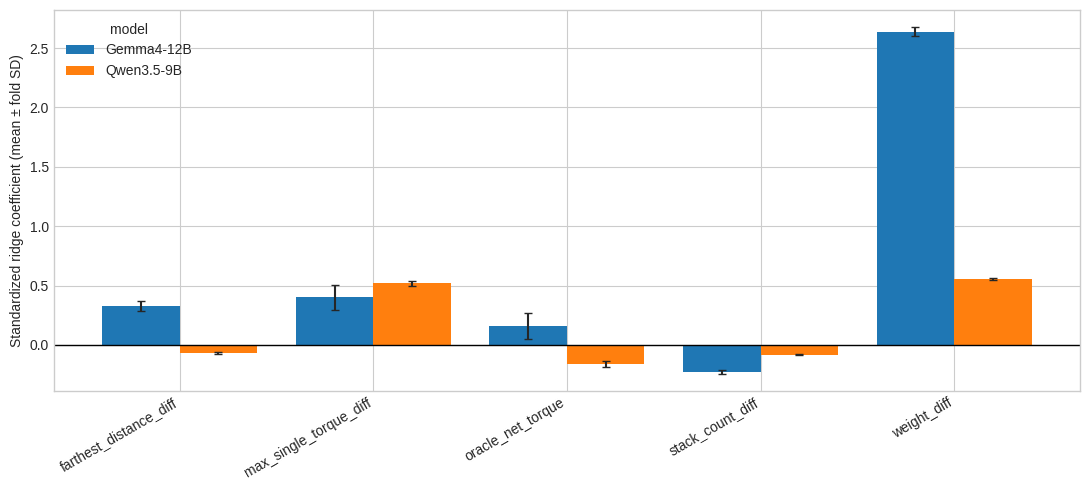

In [9]:
%%cell_progress 8/12 Fit out-of-fold margin diagnostics
cell_stage('Importing regression utilities')
try:
    from sklearn.linear_model import RidgeCV
    from sklearn.metrics import mean_absolute_error, r2_score
    from sklearn.model_selection import KFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn'])
    from sklearn.linear_model import RidgeCV
    from sklearn.metrics import mean_absolute_error, r2_score
    from sklearn.model_selection import KFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

feature_sets = {
    'physics_only': ['oracle_net_torque'],
    'shortcuts_only': [
        'weight_diff', 'farthest_distance_diff',
        'stack_count_diff', 'max_single_torque_diff',
    ],
    'physics_plus_shortcuts': [
        'oracle_net_torque', 'weight_diff', 'farthest_distance_diff',
        'stack_count_diff', 'max_single_torque_diff',
    ],
}
alphas = np.logspace(-3, 3, 13)
model_rows = []
coefficient_rows = []
for model, frame in tqdm(list(analysis_frame.groupby('model_name')), desc='Margin models', unit='model'):
    frame = frame.sort_values('scene_id').reset_index(drop=True)
    y = frame['aggregated_signed_left_right_margin'].to_numpy(dtype=float)
    splitter = KFold(n_splits=5, shuffle=True, random_state=20260817)
    for specification, columns in feature_sets.items():
        X = frame[columns].to_numpy(dtype=float)
        oof = np.empty_like(y)
        fold_coefficients = []
        selected_alphas = []
        for fold, (train, test) in enumerate(splitter.split(X), start=1):
            estimator = Pipeline([
                ('scale', StandardScaler()),
                ('ridge', RidgeCV(alphas=alphas)),
            ])
            estimator.fit(X[train], y[train])
            oof[test] = estimator.predict(X[test])
            ridge = estimator.named_steps['ridge']
            selected_alphas.append(float(ridge.alpha_))
            fold_coefficients.append(np.asarray(ridge.coef_, dtype=float))
        coefficient_matrix = np.vstack(fold_coefficients)
        correlation = float(np.corrcoef(y, oof)[0, 1]) if np.std(y) and np.std(oof) else None
        model_rows.append({
            'model': model,
            'specification': specification,
            'scene_count': len(frame),
            'oof_r2': float(r2_score(y, oof)),
            'oof_pearson': correlation,
            'oof_mae': float(mean_absolute_error(y, oof)),
            'median_selected_alpha': float(np.median(selected_alphas)),
        })
        for index, column in enumerate(columns):
            coefficient_rows.append({
                'model': model,
                'specification': specification,
                'feature': column,
                'standardized_coefficient_mean': float(coefficient_matrix[:, index].mean()),
                'standardized_coefficient_sd': float(coefficient_matrix[:, index].std(ddof=1)),
            })

margin_model_summary = pd.DataFrame(model_rows)
margin_coefficients = pd.DataFrame(coefficient_rows)
margin_model_summary.to_csv(OUTPUT_DIR / 'margin_model_summary.csv', index=False)
margin_coefficients.to_csv(OUTPUT_DIR / 'margin_model_coefficients.csv', index=False)
display(margin_model_summary.round(4))
display(margin_coefficients[margin_coefficients['specification'] == 'physics_plus_shortcuts'].round(4))

cell_stage('Computing torque-margin correlations by problem type')
correlation_rows = []
for (model, problem_type), frame in analysis_frame.groupby(['model_name', 'problem_type']):
    torque = frame['oracle_net_torque'].astype(float)
    margin = frame['aggregated_signed_left_right_margin'].astype(float)
    pearson = torque.corr(margin) if torque.nunique() > 1 and margin.nunique() > 1 else None
    spearman = torque.rank(method='average').corr(margin.rank(method='average')) if pearson is not None else None
    correlation_rows.append({
        'model': model, 'problem_type': problem_type, 'scene_count': len(frame),
        'torque_margin_pearson': pearson, 'torque_margin_spearman': spearman,
    })
torque_correlations_by_type = pd.DataFrame(correlation_rows)
torque_correlations_by_type.to_csv(OUTPUT_DIR / 'torque_correlations_by_problem_type.csv', index=False)
display(torque_correlations_by_type.sort_values(['problem_type', 'model']).round(4))

cell_stage('Plotting combined standardized coefficients')
combined = margin_coefficients[margin_coefficients['specification'] == 'physics_plus_shortcuts']
means = combined.pivot(index='feature', columns='model', values='standardized_coefficient_mean')
errors = combined.pivot(index='feature', columns='model', values='standardized_coefficient_sd').reindex_like(means)
ax = means.plot(kind='bar', yerr=errors, capsize=3, figsize=(11, 5), width=0.8)
ax.axhline(0, color='black', linewidth=1)
ax.set_ylabel('Standardized ridge coefficient (mean ± fold SD)')
ax.set_xlabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '05_margin_predictor_coefficients.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Outcome mirror equivariance

For a true left-right mirror, semantic predictions should swap and the signed left-minus-right score should change sign.


Test outcome mirror equivariance:  67%|######6   | 8/12 [00:00<?, ?cell/s]

Unique mirror scene pairs: 1033


,model,pair_count,prediction_equivariance_rate,prediction_equivariance_bootstrap_95_ci,margin_antisymmetry_pearson,margin_antisymmetry_mae,relative_antisymmetry_error
0,Gemma4-12B,1033,0.8809,"[0.8606001936108422, 0.9002904162633107]",0.8462,1.4767,0.4548
1,Qwen3.5-9B,1033,0.6699,"[0.6408518877057116, 0.6979670861568248]",0.8041,0.8130,0.9336


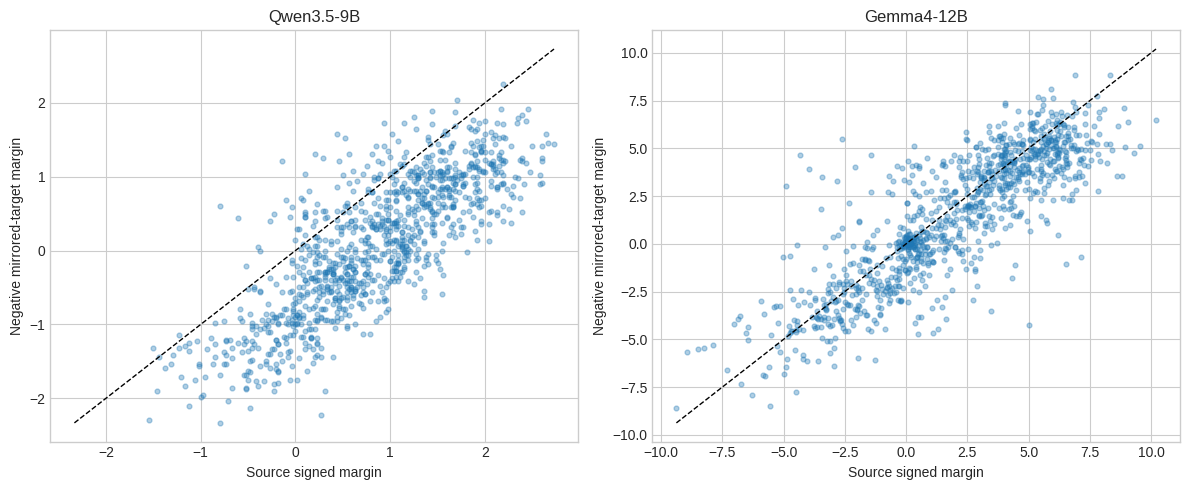

In [10]:
%%cell_progress 9/12 Test outcome mirror equivariance
cell_stage('Loading and deduplicating mirror pairs')
all_pairs = read_jsonl(DATASET_DIR / 'counterfactual_pairs.jsonl')
mirror_pairs = []
seen_scene_pairs = set()
for pair in all_pairs:
    if pair.get('edit_type') != 'mirror':
        continue
    key = tuple(sorted((str(pair['source_scene_id']), str(pair['target_scene_id']))))
    if key not in seen_scene_pairs:
        seen_scene_pairs.add(key)
        mirror_pairs.append(pair)
print('Unique mirror scene pairs:', len(mirror_pairs))

def swap_side(value):
    return {'left': 'right', 'right': 'left', 'balanced': 'balanced'}[str(value)]

def bootstrap_mean_ci(values, replicates=5000, seed=20260817):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return None
    rng = np.random.default_rng(seed)
    draws = values[rng.integers(0, len(values), size=(replicates, len(values)))].mean(axis=1)
    return [float(np.quantile(draws, 0.025)), float(np.quantile(draws, 0.975))]

cell_stage('Comparing mirrored outcome predictions')
record_index = {
    (str(row.model_name), str(row.scene_id)): row
    for row in analysis_frame.itertuples(index=False)
}
mirror_rows = []
for model in sorted(analysis_frame['model_name'].unique()):
    for pair in mirror_pairs:
        source_key = (model, str(pair['source_scene_id']))
        target_key = (model, str(pair['target_scene_id']))
        if source_key not in record_index or target_key not in record_index:
            continue
        source = record_index[source_key]
        target = record_index[target_key]
        mirror_rows.append({
            'model': model,
            'pair_id': pair['pair_id'],
            'source_scene_id': source.scene_id,
            'target_scene_id': target.scene_id,
            'source_gold': source.gold_semantic,
            'target_gold': target.gold_semantic,
            'source_prediction': source.aggregated_predicted_semantic,
            'target_prediction': target.aggregated_predicted_semantic,
            'gold_equivariant': swap_side(source.gold_semantic) == str(target.gold_semantic),
            'prediction_equivariant': swap_side(source.aggregated_predicted_semantic) == str(target.aggregated_predicted_semantic),
            'source_margin': float(source.aggregated_signed_left_right_margin),
            'target_margin': float(target.aggregated_signed_left_right_margin),
            'antisymmetry_error': abs(float(source.aggregated_signed_left_right_margin) + float(target.aggregated_signed_left_right_margin)),
        })
mirror_outcomes = pd.DataFrame(mirror_rows)
if mirror_outcomes.empty:
    raise RuntimeError('No mirror pairs overlap the completed primary runs.')
assert mirror_outcomes['gold_equivariant'].all(), 'Dataset mirror oracle failed.'
mirror_outcomes.to_csv(OUTPUT_DIR / 'mirror_outcome_pairs.csv', index=False)

summary_rows = []
for model, frame in mirror_outcomes.groupby('model'):
    equivariant = frame['prediction_equivariant'].astype(float).to_numpy()
    source_margin = frame['source_margin'].to_numpy(dtype=float)
    negative_target = -frame['target_margin'].to_numpy(dtype=float)
    denominator = np.mean((np.abs(source_margin) + np.abs(negative_target)) / 2)
    summary_rows.append({
        'model': model,
        'pair_count': len(frame),
        'prediction_equivariance_rate': float(equivariant.mean()),
        'prediction_equivariance_bootstrap_95_ci': bootstrap_mean_ci(equivariant),
        'margin_antisymmetry_pearson': (
            float(np.corrcoef(source_margin, negative_target)[0, 1])
            if np.std(source_margin) and np.std(negative_target) else None
        ),
        'margin_antisymmetry_mae': float(frame['antisymmetry_error'].mean()),
        'relative_antisymmetry_error': float(frame['antisymmetry_error'].mean() / denominator) if denominator else None,
    })
mirror_outcome_summary = pd.DataFrame(summary_rows)
mirror_outcome_summary.to_csv(OUTPUT_DIR / 'mirror_outcome_summary.csv', index=False)
display(mirror_outcome_summary.round(4))

cell_stage('Plotting mirrored signed margins')
figure, axes = plt.subplots(1, len(MODEL_SPECS), figsize=(12, 5), sharex=False, sharey=False)
for axis, spec in zip(np.atleast_1d(axes), MODEL_SPECS):
    frame = mirror_outcomes[mirror_outcomes['model'] == spec['name']]
    x = frame['source_margin'].to_numpy(dtype=float)
    y = -frame['target_margin'].to_numpy(dtype=float)
    axis.scatter(x, y, s=12, alpha=0.35)
    limits = [min(x.min(), y.min()), max(x.max(), y.max())]
    axis.plot(limits, limits, color='black', linestyle='--', linewidth=1)
    axis.set_title(spec['name'])
    axis.set_xlabel('Source signed margin')
    axis.set_ylabel('Negative mirrored-target margin')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '06_mirror_margin_equivariance.png', dpi=180, bbox_inches='tight')
plt.show()

## 8. Primitive mirror consistency

This audit swaps left-unit questions with right-unit questions, and left-distance questions with right-distance questions, across mirrored scenes.


In [11]:
%%cell_progress 10/12 Test primitive mirror consistency
cell_stage('Indexing image-condition primitive predictions')
primitive_swaps = {
    'left_units': 'right_units',
    'right_units': 'left_units',
    'left_distance': 'right_distance',
    'right_distance': 'left_distance',
}
primitive_rows = []
for spec in MODEL_SPECS:
    control_rows = [
        row for row in read_jsonl(MODEL_PATHS[spec['name']]['control'])
        if row.get('condition') == 'image_rule' and row.get('question_kind') in primitive_swaps
    ]
    index = {
        (str(row['scene_id']), str(row['question_kind'])): row
        for row in control_rows
    }
    for pair in mirror_pairs:
        source_scene = str(pair['source_scene_id'])
        target_scene = str(pair['target_scene_id'])
        for source_kind, target_kind in primitive_swaps.items():
            source_key = (source_scene, source_kind)
            target_key = (target_scene, target_kind)
            if source_key not in index or target_key not in index:
                continue
            source = index[source_key]
            target = index[target_key]
            primitive_rows.append({
                'model': spec['name'],
                'pair_id': pair['pair_id'],
                'source_kind': source_kind,
                'target_kind': target_kind,
                'source_prediction': str(source['predicted_semantic']),
                'target_prediction': str(target['predicted_semantic']),
                'source_gold': str(source['gold_semantic']),
                'target_gold': str(target['gold_semantic']),
                'prediction_swap_agreement': str(source['predicted_semantic']) == str(target['predicted_semantic']),
                'gold_swap_integrity': str(source['gold_semantic']) == str(target['gold_semantic']),
                'source_correct': bool(source['likelihood_correct']),
                'target_correct': bool(target['likelihood_correct']),
            })

primitive_mirror_pairs = pd.DataFrame(primitive_rows)
if primitive_mirror_pairs.empty:
    print('No primitive-control mirror overlap. This is an explicit missing diagnostic, not a passed check.')
    primitive_mirror_summary = pd.DataFrame(columns=[
        'model', 'primitive_family', 'pair_count', 'prediction_swap_agreement',
        'prediction_swap_bootstrap_95_ci', 'both_correct_rate', 'gold_swap_integrity_rate',
    ])
else:
    primitive_mirror_pairs['primitive_family'] = primitive_mirror_pairs['source_kind'].str.replace(r'^(left|right)_', '', regex=True)
    assert primitive_mirror_pairs['gold_swap_integrity'].all(), 'Primitive mirror oracle failed.'
    primitive_mirror_pairs.to_csv(OUTPUT_DIR / 'primitive_mirror_pairs.csv', index=False)
    rows = []
    for (model, family), frame in primitive_mirror_pairs.groupby(['model', 'primitive_family']):
        agreement = frame['prediction_swap_agreement'].astype(float).to_numpy()
        rows.append({
            'model': model,
            'primitive_family': family,
            'pair_count': len(frame),
            'prediction_swap_agreement': float(agreement.mean()),
            'prediction_swap_bootstrap_95_ci': bootstrap_mean_ci(agreement),
            'both_correct_rate': float((frame['source_correct'] & frame['target_correct']).mean()),
            'gold_swap_integrity_rate': float(frame['gold_swap_integrity'].mean()),
        })
    primitive_mirror_summary = pd.DataFrame(rows)
primitive_mirror_summary.to_csv(OUTPUT_DIR / 'primitive_mirror_summary.csv', index=False)
display(primitive_mirror_summary.round(4))

Test primitive mirror consistency:  75%|#######5  | 9/12 [00:00<?, ?cell/s]

,model,primitive_family,pair_count,prediction_swap_agreement,prediction_swap_bootstrap_95_ci,both_correct_rate,gold_swap_integrity_rate
0,Gemma4-12B,distance,16,0.6250,"[0.375, 0.875]",0.5000,1.0
1,Gemma4-12B,units,16,0.7500,"[0.5, 0.9375]",0.6875,1.0
2,Qwen3.5-9B,distance,16,0.1875,"[0.0, 0.375]",0.0000,1.0
3,Qwen3.5-9B,units,16,0.9375,"[0.8125, 1.0]",0.9375,1.0


## 9. Deterministic error gallery

The gallery is a renderer and failure-mode audit, not a mechanism for deleting inconvenient examples.


Build deterministic error gallery:  83%|########3 | 10/12 [00:00<?, ?cell/s]

Error gallery:   0%|          | 0/7 [00:00<?, ?category/s]

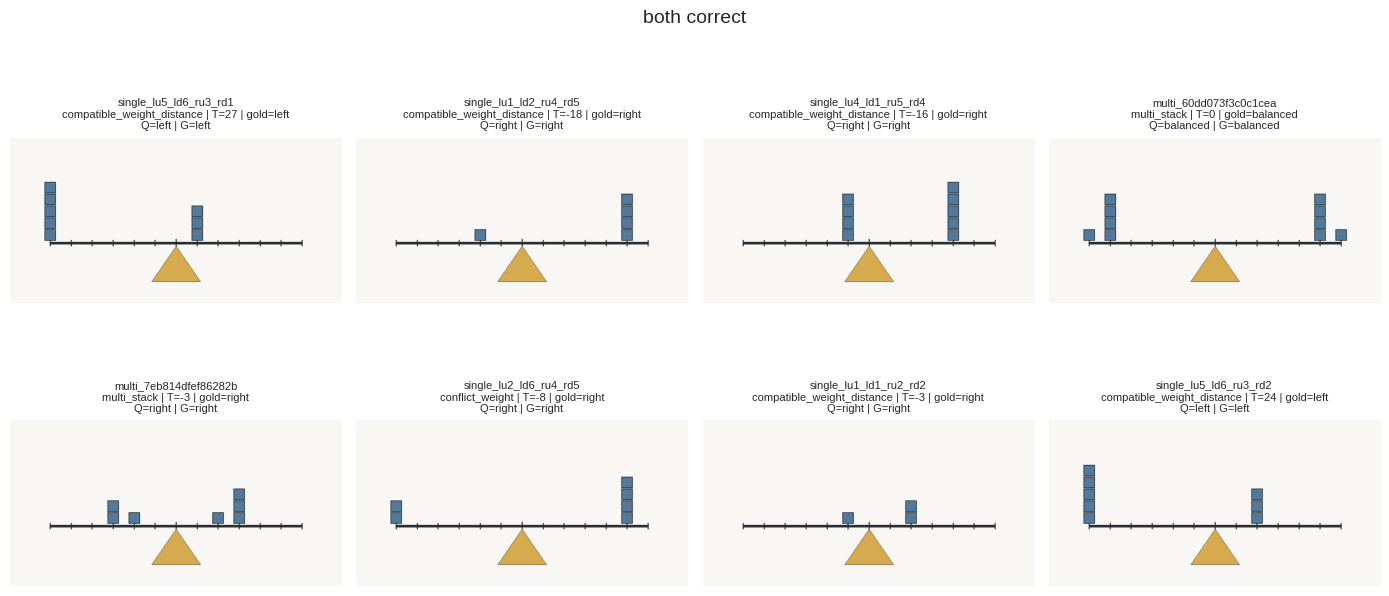

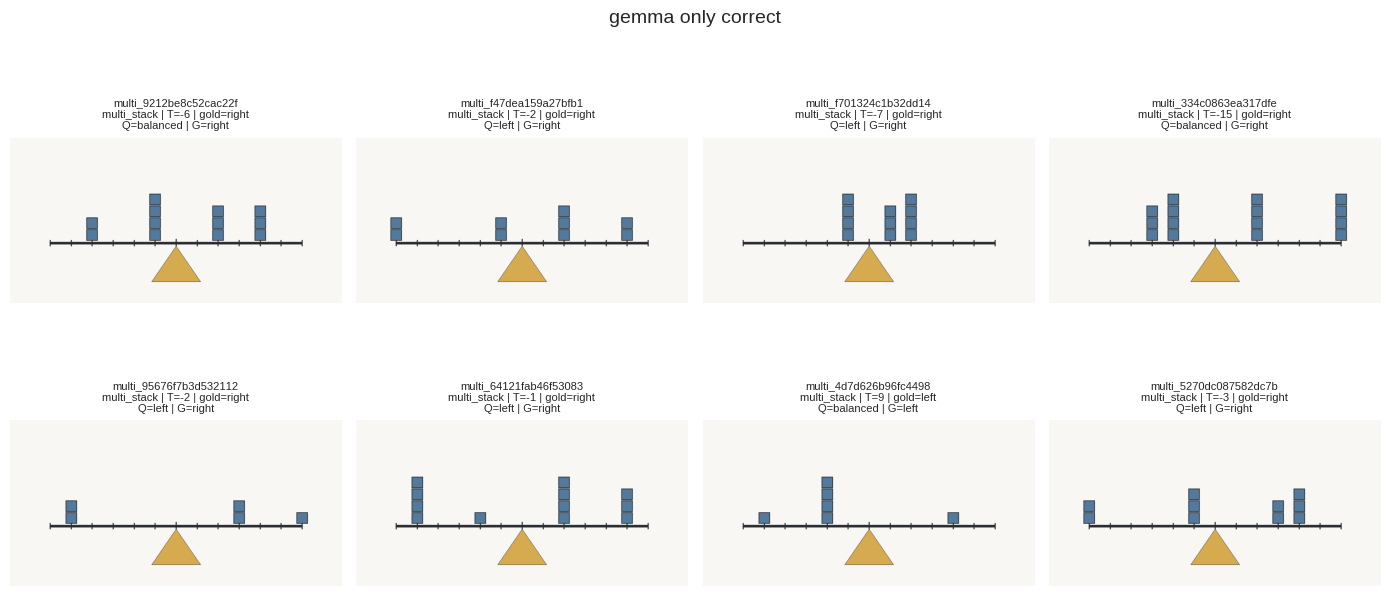

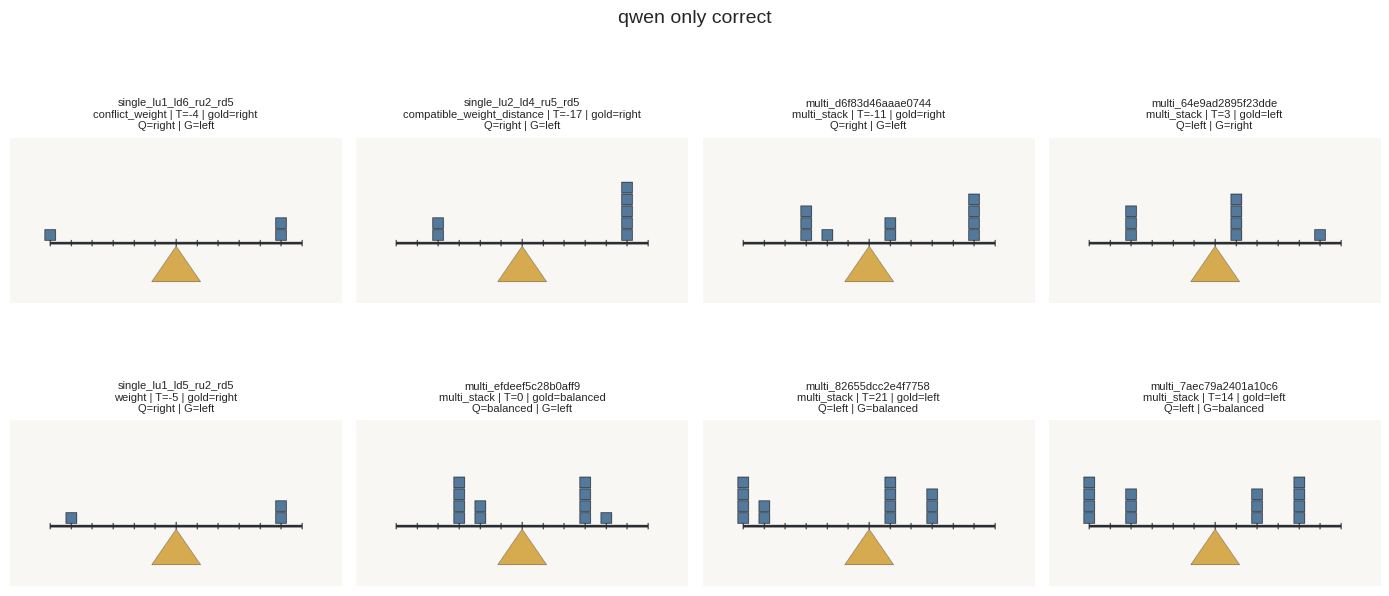

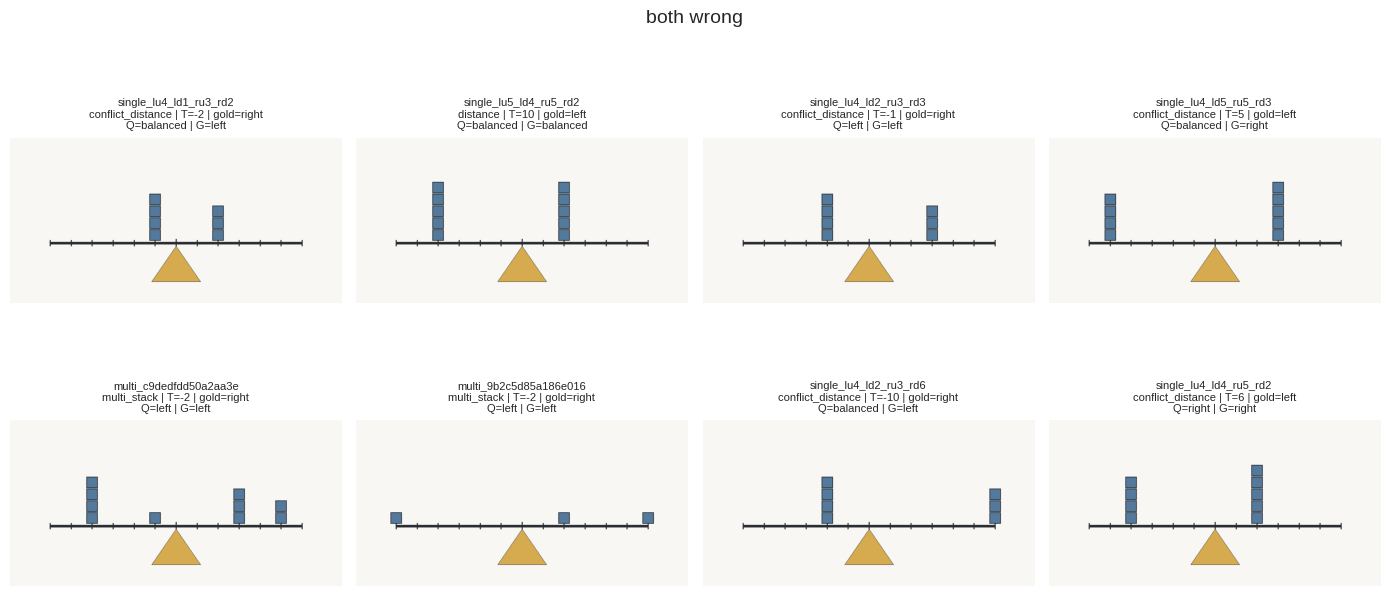

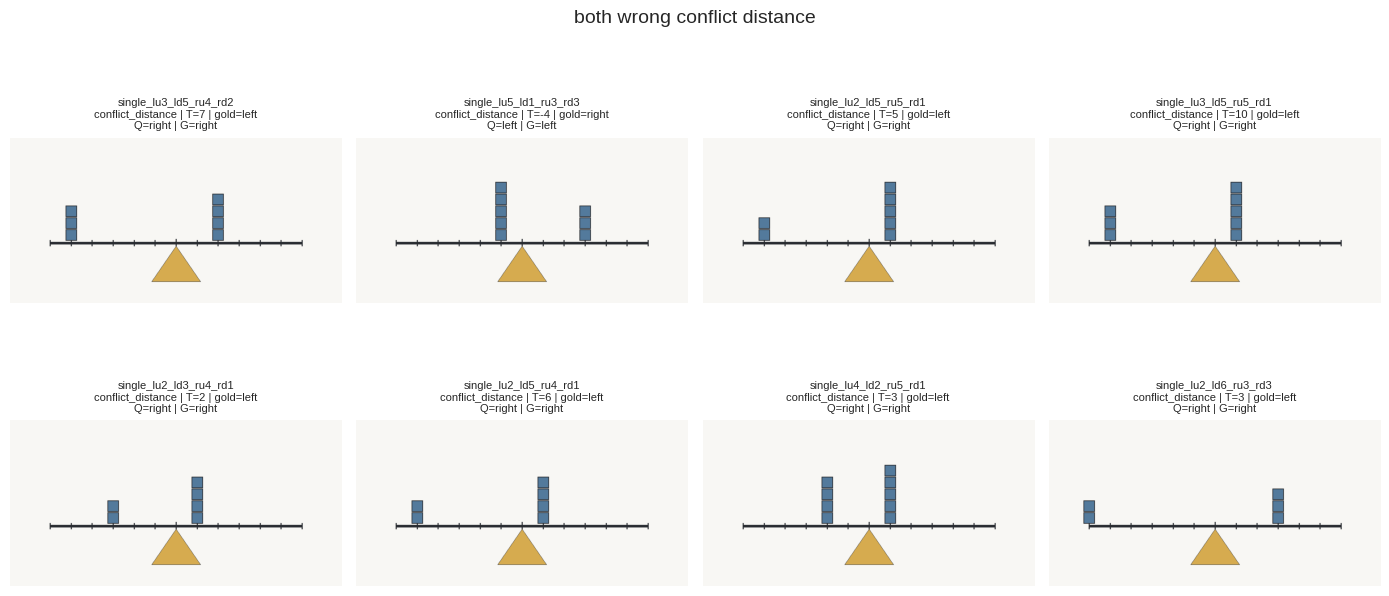

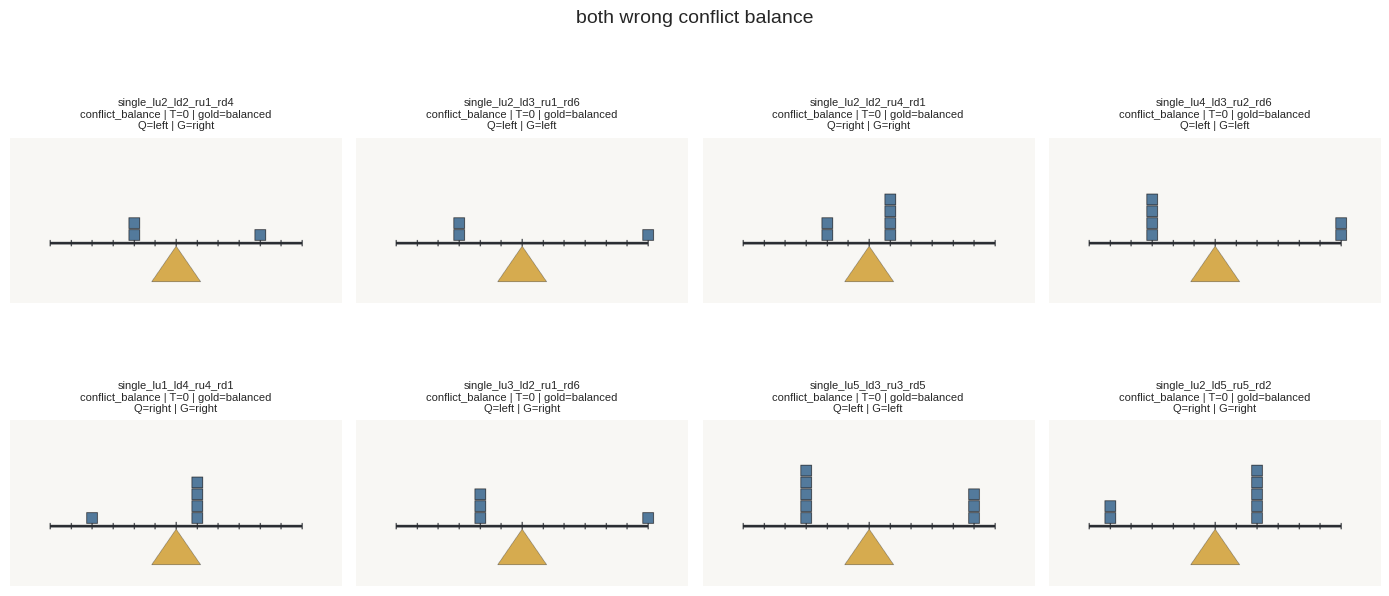

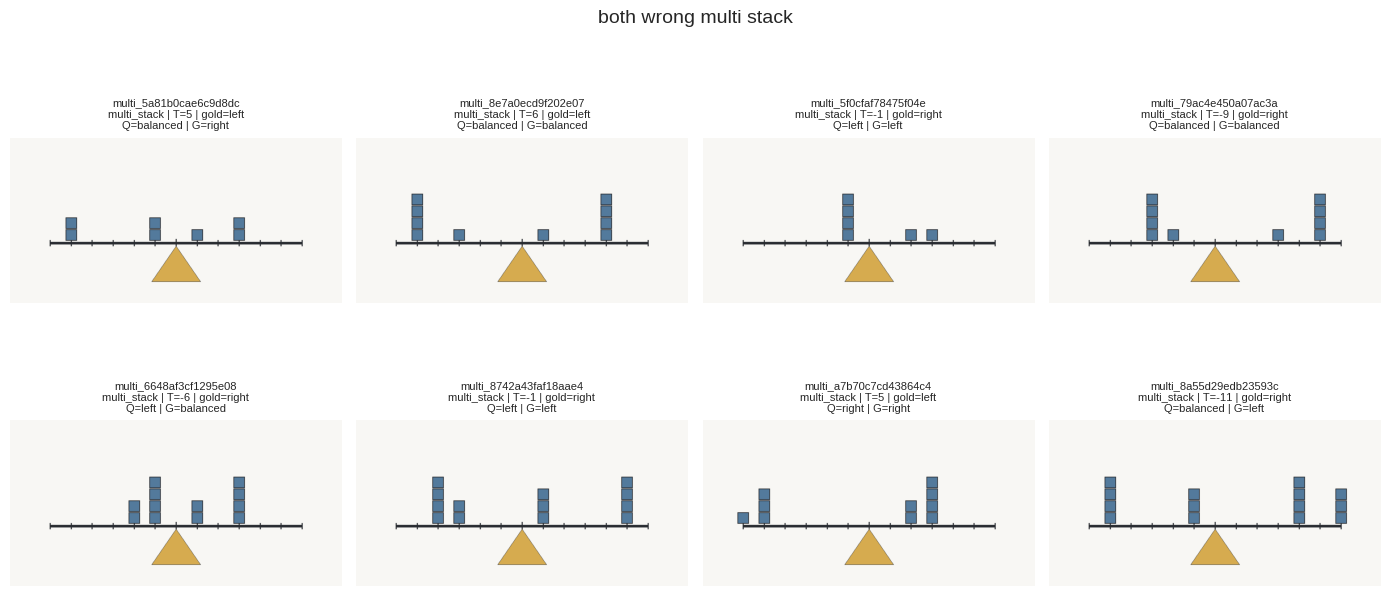

Gallery scenes: 56 | folder: /content/drive/MyDrive/VisualTorque/results/behavior_comparison_v3/error_gallery


In [12]:
%%cell_progress 11/12 Build deterministic error gallery
cell_stage('Joining cross-model scene predictions')
model_names = [spec['name'] for spec in MODEL_SPECS]
if set(model_names) != {'Qwen3.5-9B', 'Gemma4-12B'}:
    raise ValueError('Gallery category names expect the two frozen v1 models.')
by_model_scene = {
    (str(row.model_name), str(row.scene_id)): row
    for row in analysis_frame.itertuples(index=False)
}
common_scenes = sorted(
    set(analysis_frame[analysis_frame['model_name'] == model_names[0]]['scene_id'])
    & set(analysis_frame[analysis_frame['model_name'] == model_names[1]]['scene_id'])
)
gallery_source = []
for scene_id in common_scenes:
    qwen = by_model_scene[('Qwen3.5-9B', scene_id)]
    gemma = by_model_scene[('Gemma4-12B', scene_id)]
    gallery_source.append({
        'scene_id': scene_id,
        'problem_type': str(qwen.problem_type),
        'gold': str(qwen.gold_semantic),
        'net_torque': int(qwen.net_torque),
        'qwen_correct': bool(qwen.aggregated_correct),
        'gemma_correct': bool(gemma.aggregated_correct),
        'qwen_prediction': str(qwen.aggregated_predicted_semantic),
        'gemma_prediction': str(gemma.aggregated_predicted_semantic),
    })

category_rules = {
    'both_correct': lambda row: row['qwen_correct'] and row['gemma_correct'],
    'gemma_only_correct': lambda row: (not row['qwen_correct']) and row['gemma_correct'],
    'qwen_only_correct': lambda row: row['qwen_correct'] and (not row['gemma_correct']),
    'both_wrong': lambda row: (not row['qwen_correct']) and (not row['gemma_correct']),
    'both_wrong_conflict_distance': lambda row: (not row['qwen_correct']) and (not row['gemma_correct']) and row['problem_type'] == 'conflict_distance',
    'both_wrong_conflict_balance': lambda row: (not row['qwen_correct']) and (not row['gemma_correct']) and row['problem_type'] == 'conflict_balance',
    'both_wrong_multi_stack': lambda row: (not row['qwen_correct']) and (not row['gemma_correct']) and row['problem_type'] == 'multi_stack',
}
GALLERY_DIR = OUTPUT_DIR / 'error_gallery'
GALLERY_DIR.mkdir(parents=True, exist_ok=True)
gallery_manifest = []
for category, predicate in tqdm(category_rules.items(), desc='Error gallery', unit='category'):
    candidates = [row for row in gallery_source if predicate(row)]
    selected = sorted(
        candidates,
        key=lambda row: hashlib.sha256(
            f"20260817:{category}:{row['scene_id']}".encode('utf-8')
        ).hexdigest(),
    )[:8]
    if not selected:
        print(category, ': no scenes')
        continue
    columns = 4
    rows = math.ceil(len(selected) / columns)
    figure, axes = plt.subplots(rows, columns, figsize=(14, 3.5 * rows))
    axes = np.atleast_1d(axes).reshape(-1)
    for axis, row in zip(axes, selected):
        scene = scene_by_id[row['scene_id']]
        image_path = DATASET_DIR / scene['image_path']
        axis.imshow(Image.open(image_path).convert('RGB'))
        axis.set_title(
            f"{row['scene_id']}\n{row['problem_type']} | T={row['net_torque']} | gold={row['gold']}\n"
            f"Q={row['qwen_prediction']} | G={row['gemma_prediction']}",
            fontsize=8,
        )
        axis.axis('off')
        gallery_manifest.append({'category': category, **row, 'image_path': str(image_path)})
    for axis in axes[len(selected):]:
        axis.axis('off')
    figure.suptitle(category.replace('_', ' '), fontsize=14)
    plt.tight_layout()
    figure.savefig(GALLERY_DIR / f'{category}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(figure)
gallery_manifest = pd.DataFrame(gallery_manifest)
gallery_manifest.to_csv(OUTPUT_DIR / 'error_gallery_manifest.csv', index=False)
print('Gallery scenes:', len(gallery_manifest), '| folder:', GALLERY_DIR)

## 10. Freeze and verify the behavioral handoff

The final cell verifies the artifacts needed to decide whether the project can proceed to activation capture.


In [13]:
%%cell_progress 12/12 Verify and freeze Analysis v3 outputs
cell_stage('Checking required paper-facing artifacts')
required_outputs = [
    OUTPUT_DIR / 'model_summary.json',
    OUTPUT_DIR / 'paired_model_comparison.json',
    OUTPUT_DIR / 'perception_computation_diagnostics.json',
    OUTPUT_DIR / 'scene_level_predictions.jsonl',
    OUTPUT_DIR / 'activation_pilot_manifest.jsonl',
    OUTPUT_DIR / 'full_symbolic_overall.csv',
    OUTPUT_DIR / 'full_symbolic_by_problem_type.csv',
    OUTPUT_DIR / 'heuristic_signature.csv',
    OUTPUT_DIR / 'margin_model_summary.csv',
    OUTPUT_DIR / 'margin_model_coefficients.csv',
    OUTPUT_DIR / 'torque_correlations_by_problem_type.csv',
    OUTPUT_DIR / 'mirror_outcome_summary.csv',
    OUTPUT_DIR / 'primitive_mirror_summary.csv',
    OUTPUT_DIR / 'error_gallery_manifest.csv',
]
missing = [str(path) for path in required_outputs if not path.is_file()]
assert not missing, 'Missing Analysis v3 outputs:\n' + '\n'.join(missing)

cell_stage('Verifying activation discovery split isolation')
activation_manifest = pd.read_json(OUTPUT_DIR / 'activation_pilot_manifest.jsonl', lines=True)
assert set(activation_manifest['split']) <= {'probe_train', 'probe_dev'}
assert 'probe_test' not in set(activation_manifest['split'])

cell_stage('Writing reproducibility manifest')
v3_manifest = {
    'schema_version': 'behavior-analysis-v3.0',
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'dataset_dir': str(DATASET_DIR),
    'output_dir': str(OUTPUT_DIR),
    'models': [spec['name'] for spec in MODEL_SPECS],
    'scene_count_per_model': 2100,
    'bootstrap_replicates': 5000,
    'activation_discovery_scene_count': int(len(activation_manifest)),
    'activation_allowed_splits': sorted(activation_manifest['split'].unique().tolist()),
    'required_outputs': [str(path) for path in required_outputs],
    'analysis_limits': [
        'Heuristic regressions are predictive diagnostics, not mechanistic decompositions.',
        'Image-symbolic gaps do not identify a visual submodule.',
        'Mirror failures may reflect perception, prompt-side bias, or readout bias.',
        'No activation test data were used for site selection.',
    ],
}
manifest_path = OUTPUT_DIR / 'analysis_v3_manifest.json'
manifest_path.write_text(json.dumps(v3_manifest, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')

print('Behavior Analysis v3 complete.')
print('Output directory:', OUTPUT_DIR)
print('Activation discovery scenes:', len(activation_manifest))
print('Next gate: review the full-symbolic, heuristic, mirror, and gallery outputs before activation capture.')

Verify and freeze Analysis v3 outputs:  92%|#########1| 11/12 [00:00<?, ?cell/s]

Behavior Analysis v3 complete.
Output directory: /content/drive/MyDrive/VisualTorque/results/behavior_comparison_v3
Activation discovery scenes: 254
Next gate: review the full-symbolic, heuristic, mirror, and gallery outputs before activation capture.
